In [1]:
import os
import random
import time
import json
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import models, transforms, datasets
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix

In [2]:
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 42
seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[*] Perangkat yang digunakan: {device}")

# Create logging directory
os.makedirs("logs", exist_ok=True)
os.makedirs("models", exist_ok=True)

[*] Perangkat yang digunakan: cuda


In [7]:
SELECTED_CLASSES = [
    'Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British Shorthair', # 5 Kucing
    'american bulldog', 'american pit bull terrier', 'basset hound', 'beagle', 'boxer' # 5 Anjing
]

weights_res18 = models.ResNet18_Weights.IMAGENET1K_V1
norm_mean = weights_res18.transforms().mean
norm_std = weights_res18.transforms().std

# Pipeline Augmentasi Aktif (Train)
train_transform_aug = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std),
])

# Pipeline Tanpa Augmentasi (Train B4-noaug)
train_transform_noaug = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std),
])

# Pipeline Evaluasi (Val & Test)
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std),
])

print("[*] Mengunduh Oxford-IIIT Pet Dataset...")
raw_train_ds = datasets.OxfordIIITPet(root='./data', split='trainval', download=True)
raw_test_ds = datasets.OxfordIIITPet(root='./data', split='test', download=True)

# Let's clean the selected class names in case they use spaces or different casing
print("Available dataset classes sample:", raw_train_ds.classes[:10])

# Normalize names to find exact matches
normalized_dataset_classes = [c.lower().replace('_', ' ').replace(' ', '') for c in raw_train_ds.classes]

target_class_indices = []
for cls_name in SELECTED_CLASSES:
    norm_name = cls_name.lower().replace('_', ' ').replace(' ', '')
    if norm_name in normalized_dataset_classes:
        idx = normalized_dataset_classes.index(norm_name)
        target_class_indices.append(idx)
    else:
        raise ValueError(f"Class '{cls_name}' (normalized to '{norm_name}') not found in dataset!")

# Filtering 10 Kelas Target
class_to_idx = {raw_train_ds.classes[idx]: i for i, idx in enumerate(target_class_indices)}

def filter_indices(dataset):
    valid_indices = []
    labels = []
    for idx, target in enumerate(dataset._labels):
        if target in target_class_indices:
            valid_indices.append(idx)
            orig_name = dataset.classes[target]
            labels.append(class_to_idx[orig_name])
    return valid_indices, labels

trainval_indices, trainval_labels = filter_indices(raw_train_ds)
test_indices, test_labels = filter_indices(raw_test_ds)

# Pembagian Train (70%), Val (15%), Test (15%)
from sklearn.model_selection import train_test_split

train_idx, val_idx = train_test_split(
    trainval_indices, test_size=0.1765, random_state=SEED, stratify=trainval_labels
) # 0.1765 of 85% ~ 15% dari total

# Custom Dataset Wrapper
class CustomPetDataset(torch.utils.data.Dataset):
    def __init__(self, base_ds, indices, transform=None):
        self.base_ds = base_ds
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]
        img, orig_label = self.base_ds[real_idx]
        orig_name = self.base_ds.classes[orig_label]
        mapped_label = class_to_idx[orig_name]

        if self.transform:
            img = self.transform(img)
        return img, mapped_label

print(f"[*] Dataset Siap! Train: {len(train_idx)}, Val: {len(val_idx)}, Test: {len(test_indices)}")

[*] Mengunduh Oxford-IIIT Pet Dataset...
Available dataset classes sample: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair']
[*] Dataset Siap! Train: 820, Val: 176, Test: 985


In [8]:
def train_one_experiment(model, exp_code, train_ds, val_ds, test_ds, optimizer, criterion, epochs=20, patience=4):
    train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)
    test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=2)

    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_loss = float('inf')
    patience_counter = 0
    best_model_path = f"models/{exp_code}_best.pth"

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        epoch_train_loss = running_loss / total
        epoch_train_acc = correct / total

        # Validation Phase
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)

        epoch_val_loss = val_loss / val_total
        epoch_val_acc = val_correct / val_total

        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_acc'].append(epoch_val_acc)

        print(f"[{exp_code}] Epoch {epoch+1:02d}/{epochs:02d} | Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f} | Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}")

        # Early Stopping
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            patience_counter = 0
            torch.save(model.state_dict(), best_model_path)
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"[*] Early stopping dipicu pada epoch {epoch+1}")
                break

    total_time = time.time() - start_time

    # Test Evaluation
    model.load_state_dict(torch.load(best_model_path))
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    test_acc = accuracy_score(all_labels, all_preds)
    test_f1 = f1_score(all_labels, all_preds, average='macro')

    metrics_summary = {
        'exp_code': exp_code,
        'trainable_params': trainable_params,
        'total_params': total_params,
        'epochs_converged': len(history['train_loss']),
        'total_time_sec': round(total_time, 2),
        'best_val_acc': max(history['val_acc']),
        'test_acc': test_acc,
        'test_macro_f1': test_f1
    }

    return metrics_summary, history, all_preds, all_labels

In [9]:
results_summary = []
histories = {}

# Datasets
ds_train_aug = CustomPetDataset(raw_train_ds, train_idx, transform=train_transform_aug)
ds_train_noaug = CustomPetDataset(raw_train_ds, train_idx, transform=train_transform_noaug)
ds_val = CustomPetDataset(raw_train_ds, val_idx, transform=eval_transform)
ds_test = CustomPetDataset(raw_test_ds, test_indices, transform=eval_transform)

# --- B1: Baseline From Scratch ---
print("\n=== Menjalankan B1: Baseline From Scratch ===")
model_b1 = models.resnet18(weights=None)
model_b1.fc = nn.Linear(model_b1.fc.in_features, 10)
model_b1.to(device)
opt_b1 = optim.AdamW(model_b1.parameters(), lr=1e-3, weight_decay=1e-2)
res_b1, hist_b1, _, _ = train_one_experiment(model_b1, 'B1_Scratch', ds_train_aug, ds_val, ds_test, opt_b1, nn.CrossEntropyLoss())
results_summary.append(res_b1); histories['B1'] = hist_b1

# --- B2: Feature Extraction ---
print("\n=== Menjalankan B2: Feature Extraction ===")
model_b2 = models.resnet18(weights=weights_res18)
for param in model_b2.parameters():
    param.requires_grad = False
model_b2.fc = nn.Linear(model_b2.fc.in_features, 10)
model_b2.to(device)
opt_b2 = optim.AdamW(model_b2.fc.parameters(), lr=1e-3, weight_decay=1e-2)
res_b2, hist_b2, _, _ = train_one_experiment(model_b2, 'B2_FeatureExtract', ds_train_aug, ds_val, ds_test, opt_b2, nn.CrossEntropyLoss())
results_summary.append(res_b2); histories['B2'] = hist_b2

# --- B3: Progressive Fine-Tuning ---
print("\n=== Menjalankan B3: Progressive Fine-Tuning ===")
model_b3 = models.resnet18(weights=weights_res18)
for param in model_b3.parameters():
    param.requires_grad = False
for param in model_b3.layer4.parameters():
    param.requires_grad = True
model_b3.fc = nn.Linear(model_b3.fc.in_features, 10)
model_b3.to(device)
opt_b3 = optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)
res_b3, hist_b3, best_b3_preds, best_b3_labels = train_one_experiment(model_b3, 'B3_FineTune', ds_train_aug, ds_val, ds_test, opt_b3, nn.CrossEntropyLoss())
results_summary.append(res_b3); histories['B3'] = hist_b3

# --- B4: Kontrol Data Augmentasi (Tanpa Augmentasi pada B3) ---
print("\n=== Menjalankan B4: Fine-Tuning Tanpa Augmentasi ===")
model_b4 = models.resnet18(weights=weights_res18)
for param in model_b4.parameters():
    param.requires_grad = False
for param in model_b4.layer4.parameters():
    param.requires_grad = True
model_b4.fc = nn.Linear(model_b4.fc.in_features, 10)
model_b4.to(device)
opt_b4 = optim.AdamW([
    {"params": model_b4.layer4.parameters(), "lr": 1e-4},
    {"params": model_b4.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)
res_b4, hist_b4, _, _ = train_one_experiment(model_b4, 'B4_NoAug', ds_train_noaug, ds_val, ds_test, opt_b4, nn.CrossEntropyLoss())
results_summary.append(res_b4); histories['B4'] = hist_b4

# --- B5: Arsitektur Pembanding (EfficientNet-B0) ---
print("\n=== Menjalankan B5: Arsitektur Pembanding EfficientNet-B0 ===")
weights_eff = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model_b5 = models.efficientnet_b0(weights=weights_eff)
for param in model_b5.parameters():
    param.requires_grad = False
# Unfreeze top feature block & classifier
for param in model_b5.features[7].parameters():
    param.requires_grad = True
model_b5.classifier[1] = nn.Linear(model_b5.classifier[1].in_features, 10)
model_b5.to(device)
opt_b5 = optim.AdamW([
    {"params": model_b5.features[7].parameters(), "lr": 1e-4},
    {"params": model_b5.classifier.parameters(), "lr": 1e-3}
], weight_decay=1e-2)
res_b5, hist_b5, _, _ = train_one_experiment(model_b5, 'B5_EfficientNetB0', ds_train_aug, ds_val, ds_test, opt_b5, nn.CrossEntropyLoss())
results_summary.append(res_b5); histories['B5'] = hist_b5


=== Menjalankan B1: Baseline From Scratch ===
[B1_Scratch] Epoch 01/20 | Train Loss: 2.5119 Acc: 0.1707 | Val Loss: 5.0405 Acc: 0.1648
[B1_Scratch] Epoch 02/20 | Train Loss: 2.1730 Acc: 0.2195 | Val Loss: 2.2952 Acc: 0.2045
[B1_Scratch] Epoch 03/20 | Train Loss: 2.0686 Acc: 0.2500 | Val Loss: 2.3880 Acc: 0.1932
[B1_Scratch] Epoch 04/20 | Train Loss: 1.9623 Acc: 0.3024 | Val Loss: 2.1093 Acc: 0.2727
[B1_Scratch] Epoch 05/20 | Train Loss: 1.8945 Acc: 0.3305 | Val Loss: 2.2136 Acc: 0.2273
[B1_Scratch] Epoch 06/20 | Train Loss: 1.8896 Acc: 0.3220 | Val Loss: 2.2195 Acc: 0.2784
[B1_Scratch] Epoch 07/20 | Train Loss: 1.7461 Acc: 0.4024 | Val Loss: 1.9935 Acc: 0.3011
[B1_Scratch] Epoch 08/20 | Train Loss: 1.7725 Acc: 0.3878 | Val Loss: 1.9931 Acc: 0.3693
[B1_Scratch] Epoch 09/20 | Train Loss: 1.7233 Acc: 0.3817 | Val Loss: 1.8557 Acc: 0.3636
[B1_Scratch] Epoch 10/20 | Train Loss: 1.6790 Acc: 0.4207 | Val Loss: 2.5142 Acc: 0.2500
[B1_Scratch] Epoch 11/20 | Train Loss: 1.7121 Acc: 0.4171 | Val

100%|██████████| 44.7M/44.7M [00:00<00:00, 147MB/s]


[B2_FeatureExtract] Epoch 01/20 | Train Loss: 1.8785 Acc: 0.3573 | Val Loss: 1.3189 Acc: 0.6420
[B2_FeatureExtract] Epoch 02/20 | Train Loss: 1.0920 Acc: 0.7159 | Val Loss: 0.9017 Acc: 0.7443
[B2_FeatureExtract] Epoch 03/20 | Train Loss: 0.7737 Acc: 0.8195 | Val Loss: 0.6773 Acc: 0.8466
[B2_FeatureExtract] Epoch 04/20 | Train Loss: 0.5974 Acc: 0.8720 | Val Loss: 0.5624 Acc: 0.8523
[B2_FeatureExtract] Epoch 05/20 | Train Loss: 0.4950 Acc: 0.9061 | Val Loss: 0.5084 Acc: 0.8409
[B2_FeatureExtract] Epoch 06/20 | Train Loss: 0.4590 Acc: 0.8878 | Val Loss: 0.4471 Acc: 0.8977
[B2_FeatureExtract] Epoch 07/20 | Train Loss: 0.3956 Acc: 0.9159 | Val Loss: 0.4303 Acc: 0.9034
[B2_FeatureExtract] Epoch 08/20 | Train Loss: 0.3881 Acc: 0.8988 | Val Loss: 0.4016 Acc: 0.8864
[B2_FeatureExtract] Epoch 09/20 | Train Loss: 0.3607 Acc: 0.9073 | Val Loss: 0.3764 Acc: 0.8977
[B2_FeatureExtract] Epoch 10/20 | Train Loss: 0.3072 Acc: 0.9329 | Val Loss: 0.3588 Acc: 0.9205
[B2_FeatureExtract] Epoch 11/20 | Train 

100%|██████████| 20.5M/20.5M [00:00<00:00, 166MB/s]


[B5_EfficientNetB0] Epoch 01/20 | Train Loss: 1.7394 Acc: 0.5683 | Val Loss: 0.9817 Acc: 0.8523
[B5_EfficientNetB0] Epoch 02/20 | Train Loss: 0.8241 Acc: 0.8451 | Val Loss: 0.5842 Acc: 0.8693
[B5_EfficientNetB0] Epoch 03/20 | Train Loss: 0.5161 Acc: 0.8890 | Val Loss: 0.4477 Acc: 0.8693
[B5_EfficientNetB0] Epoch 04/20 | Train Loss: 0.3790 Acc: 0.9122 | Val Loss: 0.3729 Acc: 0.8920
[B5_EfficientNetB0] Epoch 05/20 | Train Loss: 0.2978 Acc: 0.9402 | Val Loss: 0.3270 Acc: 0.8977
[B5_EfficientNetB0] Epoch 06/20 | Train Loss: 0.2513 Acc: 0.9341 | Val Loss: 0.3048 Acc: 0.9034
[B5_EfficientNetB0] Epoch 07/20 | Train Loss: 0.2099 Acc: 0.9537 | Val Loss: 0.2837 Acc: 0.9091
[B5_EfficientNetB0] Epoch 08/20 | Train Loss: 0.1966 Acc: 0.9512 | Val Loss: 0.2699 Acc: 0.9205
[B5_EfficientNetB0] Epoch 09/20 | Train Loss: 0.1768 Acc: 0.9524 | Val Loss: 0.2760 Acc: 0.9034
[B5_EfficientNetB0] Epoch 10/20 | Train Loss: 0.1473 Acc: 0.9671 | Val Loss: 0.2551 Acc: 0.9148
[B5_EfficientNetB0] Epoch 11/20 | Train 

In [10]:
df_results = pd.DataFrame(results_summary)
df_results.to_csv("logs/metrics_summary.csv", index=False)

with open("logs/metrics_summary.json", "w") as f:
    json.dump(results_summary, f, indent=4)

print("\n[+] Berhasil menyimpan log metrik mentah ke 'logs/metrics_summary.csv'")
print(df_results.to_string())


[+] Berhasil menyimpan log metrik mentah ke 'logs/metrics_summary.csv'
            exp_code  trainable_params  total_params  epochs_converged  total_time_sec  best_val_acc  test_acc  test_macro_f1
0         B1_Scratch          11181642      11181642                13          109.04      0.369318  0.357360       0.330637
1  B2_FeatureExtract              5130      11181642                20          149.22      0.937500  0.875127       0.875523
2        B3_FineTune           8398858      11181642                11           82.92      0.948864  0.879188       0.878124
3           B4_NoAug           8398858      11181642                12           58.37      0.937500  0.897462       0.897496
4  B5_EfficientNetB0            730042       4020358                20          153.24      0.937500  0.887310       0.886684


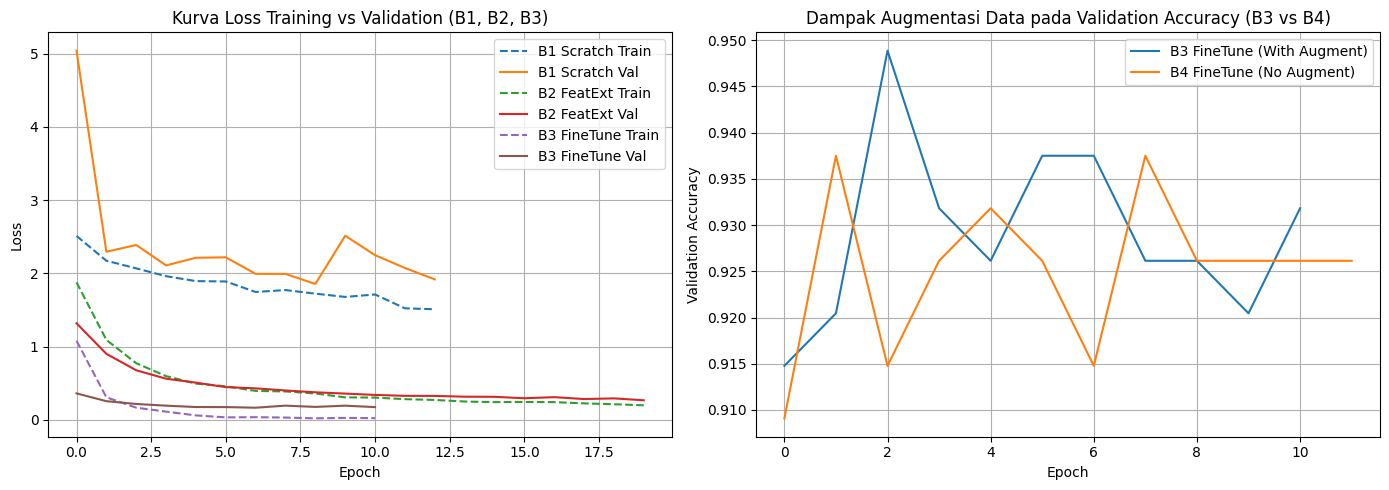

In [11]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(histories['B1']['train_loss'], label='B1 Scratch Train', linestyle='--')
plt.plot(histories['B1']['val_loss'], label='B1 Scratch Val')
plt.plot(histories['B2']['train_loss'], label='B2 FeatExt Train', linestyle='--')
plt.plot(histories['B2']['val_loss'], label='B2 FeatExt Val')
plt.plot(histories['B3']['train_loss'], label='B3 FineTune Train', linestyle='--')
plt.plot(histories['B3']['val_loss'], label='B3 FineTune Val')
plt.title("Kurva Loss Training vs Validation (B1, B2, B3)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(histories['B3']['val_acc'], label='B3 FineTune (With Augment)')
plt.plot(histories['B4']['val_acc'], label='B4 FineTune (No Augment)')
plt.title("Dampak Augmentasi Data pada Validation Accuracy (B3 vs B4)")
plt.xlabel("Epoch"); plt.ylabel("Validation Accuracy"); plt.legend(); plt.grid(True)

plt.tight_layout()
plt.savefig("logs/training_curves.png")
plt.show()


=== Menjalankan Failure Analysis pada Model Terbaik (B3) ===


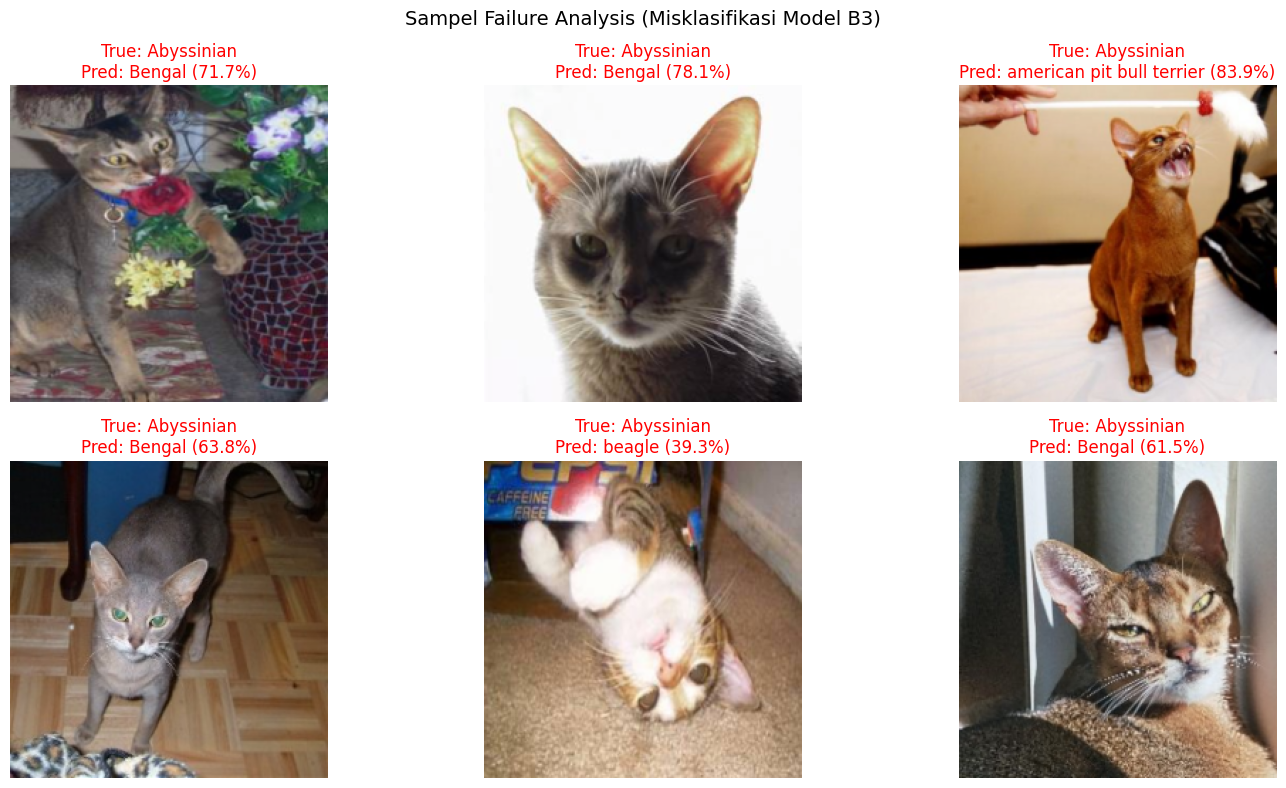

In [12]:
print("\n=== Menjalankan Failure Analysis pada Model Terbaik (B3) ===")
model_b3.load_state_dict(torch.load("models/B3_FineTune_best.pth"))
model_b3.eval()

test_loader = DataLoader(ds_test, batch_size=1, shuffle=False)
misclassified = []

with torch.no_grad():
    for idx, (img_tensor, label) in enumerate(test_loader):
        img_tensor = img_tensor.to(device)
        outputs = model_b3(img_tensor)
        probs = torch.softmax(outputs, dim=1)
        conf, pred = torch.max(probs, 1)

        if pred.item() != label.item():
            misclassified.append({
                'idx': idx,
                'img_tensor': img_tensor.cpu().squeeze(0),
                'true_label': SELECTED_CLASSES[label.item()],
                'pred_label': SELECTED_CLASSES[pred.item()],
                'confidence': conf.item()
            })
        if len(misclassified) >= 6:
            break

# Plot Gambar Misklasifikasi
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, item in enumerate(misclassified):
    ax = axes[i//3, i%3]
    # Unnormalize image for visualization
    img_np = item['img_tensor'].numpy().transpose((1, 2, 0))
    img_np = np.array(norm_std) * img_np + np.array(norm_mean)
    img_np = np.clip(img_np, 0, 1)

    ax.imshow(img_np)
    ax.set_title(f"True: {item['true_label']}\nPred: {item['pred_label']} ({item['confidence']*100:.1f}%)", color='red')
    ax.axis('off')

plt.suptitle("Sampel Failure Analysis (Misklasifikasi Model B3)", fontsize=14)
plt.tight_layout()
plt.savefig("logs/failure_analysis.png")
plt.show()